# Lesson 26 - Unknown ships with the CNN, merchant vessels merged, judged per ship

A hydrophone hears every ship, also the types our models were never trained on. Lesson 21 (section B) tested
whether gradient boosting can say **"unknown"** for those ships when it is unsure. This lesson asks the same of the
best network: **lesson 17's EfficientNet-B0 fused with 139 engineered numbers**, five known classes with the
merchant vessels merged (background, cargo + tanker, fishing, pleasure craft, tug), and judges it **per ship**.

| | |
|---|---|
| **Known** | the five classes, test ships of lesson 17's folds (69.0 % per clip, 76.4 % per ship there) |
| **Unknown** | every ship of the six left-out types: sailing, the dataset's "other", passenger ship, rescue, dredger, pilot vessel (522 ships). The five fold models never heard any of them |
| **Confidence of a ship** | the highest class probability after averaging the ship's clips |
| **Threshold** | set on the **validation** fold (known ships the model was not trained on): 95 % of them stay above it. A test ship below it is called "unknown" |

No new training: the five saved fold models are run on their validation fold, their test fold, and the left-out
ships of the same fold, so every left-out ship is tested exactly once. For comparison, lesson 21's gradient
boosting (144 engineered numbers) is scored with exactly the same rules.

| Section | Question |
|---|---|
| 1. The ships | how many known and unknown ships are tested |
| 2. Can confidence tell them apart? | per-ship confidence, AUROC |
| 3. With the threshold | which unknown ships are caught, which known ships are lost |
| 4. One number per ship | accuracy when "unknown" is a sixth answer |
| 5. What it means | |

```
python src/unknown_cnn.py               # -> runs/unknown_cnn/ (GPU, inference only)
python src/unknown_cnn.py --reference   # lesson 21's gradient boosting, same rules (CPU, a few minutes)
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import open_set as O
import unknown_cnn as U
from paths import RUNS_DIR

OUT = RUNS_DIR / "unknown_cnn"
cnn = json.loads((OUT / "results.json").read_text())
res = {"CNN + engineered": pd.DataFrame(cnn["results"])}
if (OUT / "reference.json").exists():          # python src/unknown_cnn.py --reference (CPU)
    res["gradient boosting"] = pd.DataFrame(json.loads((OUT / "reference.json").read_text())["results"])
else:
    print("gradient-boosting reference not run yet: only the CNN is shown (lesson 21: AUROC per ship 83.1 %)")
preds = pd.read_parquet(OUT / "predictions.parquet")
P = [f"p_{n}" for n in U.NAMES]
pd.set_option("display.width", 160)
CNN_C, GB_C, UNK_C = "#0f6fff", "#eb6834", "#b03a2e"

D:\shipsound\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gradient-boosting reference not run yet: only the CNN is shown (lesson 21: AUROC per ship 83.1 %)


## 1. The ships

Ships tested in each round (known: lesson 17's test fold; unknown: the left-out ships of the same fold):

In [2]:
r = res["CNN + engineered"]
print(r[["fold", "n_known_ships", "n_unknown_ships", "n_unknown_clips"]].to_string(index=False))
u = preds[preds.split == "unknown"]
print("\nunknown ships by type:", u.groupby("label").ship.nunique().sort_values(ascending=False).to_dict())

 fold  n_known_ships  n_unknown_ships  n_unknown_clips
    1            901              107             6608
    2            900              104             4433
    3            900              104             4444
    4            899              102             3069
    5            898              105             3050

unknown ships by type: {'sailing': 212, 'other': 169, 'passengership': 110, 'rescue': 23, 'dredger': 6, 'pilotvessel': 2}


## 2. Can confidence tell them apart?

Each ship's confidence (its clips averaged). If the model is surer about ships it knows, the known ships sit to
the right.

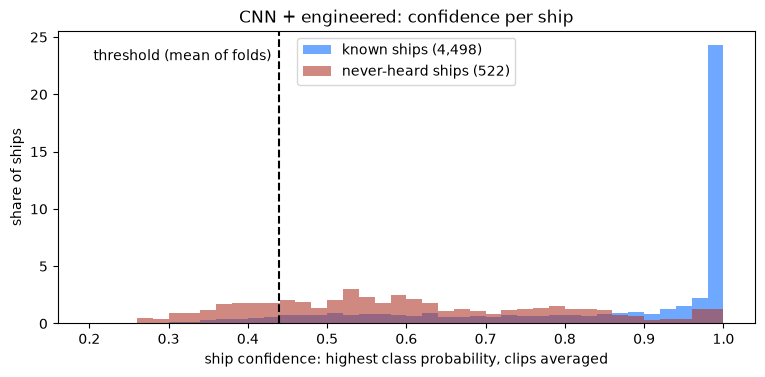

In [3]:
def ship_conf(df):
    s = df.groupby("ship")[P].mean()
    return s.max(axis=1)


known_conf = ship_conf(preds[preds.split == "test"])
unknown_conf = ship_conf(u)
thr = r.threshold_ship.mean()
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0.2, 1, 41)
ax.hist(known_conf, bins, alpha=0.6, color=CNN_C, label=f"known ships ({len(known_conf):,})", density=True)
ax.hist(unknown_conf, bins, alpha=0.6, color=UNK_C, label=f"never-heard ships ({len(unknown_conf):,})", density=True)
ax.axvline(thr, color="black", ls="--"); ax.text(thr - 0.01, ax.get_ylim()[1] * 0.9, "threshold (mean of folds)",
                                                  ha="right")
ax.set_xlabel("ship confidence: highest class probability, clips averaged"); ax.set_ylabel("share of ships")
ax.legend(); ax.set_title("CNN + engineered: confidence per ship"); plt.show()

**AUROC** is the chance that a random never-heard ship gets a lower confidence than a random known ship (50 % =
no help, 100 % = perfect). Mean over the five folds (± spread between folds):

In [4]:
def show(cols, scale=100):
    rows = {}
    for name, df in res.items():
        rows[name] = {c: f"{scale * df[c].mean():.1f} ± {scale * df[c].std():.1f}" for c in cols}
    return pd.DataFrame(rows).T


print(show(["auroc_ship", "auroc_clip"]).to_string())
print("\nAUROC per ship by left-out type (mean over folds):")
print(pd.DataFrame({n: pd.DataFrame(list(df.auroc_ship_by_type)).mean() for n, df in res.items()}).mul(100)
      .round(1).to_string())

                  auroc_ship  auroc_clip
CNN + engineered  81.7 ± 2.5  66.4 ± 2.5

AUROC per ship by left-out type (mean over folds):
               CNN + engineered
dredger                    83.0
other                      79.8
passengership              83.7
pilotvessel                90.8
rescue                     88.7
sailing                    81.4


## 3. With the threshold

The threshold keeps 95 % of the known validation ships. On the test ships:

                 known_ships_accepted unknown_ships_rejected known_clips_accepted unknown_clips_rejected
CNN + engineered           95.0 ± 0.7             22.3 ± 9.2           95.2 ± 0.6              9.3 ± 2.8


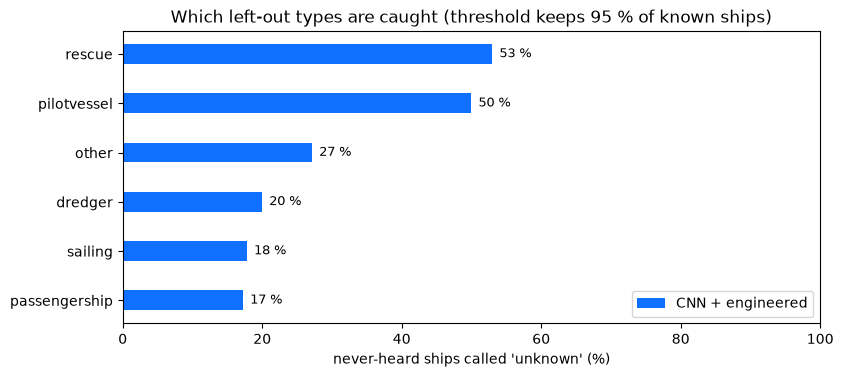

known test ships called 'unknown', by class (CNN):
background         3.4
cargo + tanker     1.1
fishing           26.1
pleasurecraft     13.8
tug               16.5

never-heard ships NOT caught: what the CNN calls them (share of all unknown ships):
background         9.2
cargo + tanker    12.3
fishing           10.1
pleasurecraft     32.1
tug               13.9


In [5]:
print(show(["known_ships_accepted", "unknown_ships_rejected", "known_clips_accepted", "unknown_clips_rejected"])
      .to_string())

rej = {n: pd.DataFrame(list(df.unknown_ships_rejected_by_type)).mean() for n, df in res.items()}
rej = pd.DataFrame(rej).sort_values("CNN + engineered")
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(rej))
shift = {"CNN + engineered": 0.2 if len(res) > 1 else 0, "gradient boosting": -0.2}
for name, color in (("CNN + engineered", CNN_C), ("gradient boosting", GB_C)):
    if name not in rej:
        continue
    ax.barh(y + shift[name], 100 * rej[name], 0.4, color=color, label=name)
    for yy, v in zip(y, rej[name]):
        ax.text(100 * v + 1, yy + shift[name], f"{100 * v:.0f} %", va="center", fontsize=9)
ax.set_yticks(y, rej.index); ax.set_xlabel("never-heard ships called 'unknown' (%)"); ax.set_xlim(0, 100)
ax.legend(loc="lower right"); ax.set_title("Which left-out types are caught (threshold keeps 95 % of known ships)")
plt.show()

print("known test ships called 'unknown', by class (CNN):")
print((100 * pd.DataFrame(list(res["CNN + engineered"].known_ships_rejected_by_class)).mean()).round(1).to_string())
print("\nnever-heard ships NOT caught: what the CNN calls them (share of all unknown ships):")
print((100 * pd.DataFrame(list(res["CNN + engineered"].unknown_ships_called_as)).mean()).round(1).to_string())

## 4. One number per ship

With "unknown" as a sixth answer, every test ship is either right or wrong:

- a **known** ship is right only if it is accepted (above the threshold) **and** given its correct class;
- a **never-heard** ship is right if it is called "unknown".

The open-set accuracy is the mean of the six per-class shares (each class counts the same, as balanced accuracy).
"Closed" is the usual five-class per-ship score on the known ships only (no threshold, no unknown ships).

In [6]:
print(show(["open_set_per_ship_balanced_accuracy", "closed_per_ship_balanced_accuracy"]).to_string())
print("\nper-class shares (open set, mean over folds):")
print(pd.DataFrame({n: pd.DataFrame(list(df.open_set_per_ship_recall)).mean() for n, df in res.items()})
      .mul(100).round(1).to_string())

                 open_set_per_ship_balanced_accuracy closed_per_ship_balanced_accuracy
CNN + engineered                          62.7 ± 1.2                        76.4 ± 1.5

per-class shares (open set, mean over folds):
                CNN + engineered
background                  89.7
cargo + tanker              95.5
fishing                     35.3
pleasurecraft               66.0
tug                         67.6
unknown                     22.3


## 5. What it means

| CNN + engineered, 5 classes (merchant merged), 5 folds | Per ship | Per clip |
|---|---|---|
| AUROC known vs never heard | **81.7 ± 2.5 %** (gradient boosting, lesson 21: 83.1 %) | 66.4 % (GB: 67.0 %) |
| known ships kept at the threshold | 95.0 % | 95.2 % |
| never-heard ships called "unknown" | **22.3 %** (fold spread 12-35 %) | 9.3 % |
| accuracy with "unknown" as a sixth answer | **62.7 %** (five known classes alone: 76.4 %) | |

- **Judging per ship helps a lot**, for the CNN as for gradient boosting: averaging a ship's clips lifts AUROC from
  66 % to 82 %, and the share of unknown ships caught at the same cost from 9 % to 22 %.
- **The CNN is not better at it than gradient boosting** (81.7 against 83.1 % AUROC per ship). Lesson 17 found the
  same for recognising the known classes.
- **Most never-heard ships still get a confident answer.** At a threshold that loses 5 % of known ships, about 4 in
  5 never-heard ships pass as one of the five classes, most often pleasure craft. Rescue boats are caught most often
  (12 of 23); sailing boats, passenger ships and dredgers least (17-18 %).
- **The known ships it loses are the weak classes:** 26 % of fishing boats, 17 % of tugs, 14 % of pleasure craft are
  called "unknown", but only 1 % of merchant ships and 3 % of background days.
- A stricter threshold catches more unknown ships only by losing more known ones (the curves of section 2). Low
  confidence alone is a weak unknown detector here; lesson 22's "other" class (always in from now on) answers the
  same question by training on the left-out types.